# Sous-apprentissage, sur-apprentissage et double descente

Ce notebook est inspiré de https://windowsontheory.org/2019/12/05/deep-double-descent/

L'objectif ici est d'essayer d'illustrer les concepts de sous-apprentissage, sur-apprentissage et de double descente. 

## Génération des données

Nous allons commencer par générer des données selon un modèle donné. Ces données sont tirées selon un polynôme de Legendre (pas important ici).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

/usr/local/lib/python3.12/dist-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
rseed = 2024
np.random.seed(rseed) # nous allons pouvoir tous tirer les mêmes données pour commenter les résultats

#quelques fonctions utiles pour tirer les points
def cubic_gt(x, beta=np.array([0, -1, 0, 1])):
  return poly(x, beta.shape[0] - 1).dot(beta)
def poly(pts, d):
  return np.polynomial.legendre.legvander(pts, d)

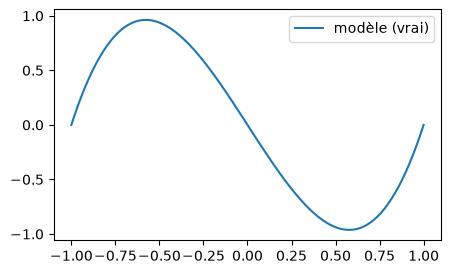

In [14]:
n = 20 
x_true = np.linspace(-1, 1, 100) # points to plot
y_true = cubic_gt(x_true)

plt.figure(figsize=(5, 3))
plt.plot(x_true, y_true, label='modèle (vrai)')
plt.legend()
plt.show()


Ce modèle est le modèle "vrai", c'est-à-dire qu'il représente le vrai phénomène. En pratique, les données que l'on collecte sont bruitées et peuvent être corrompues par des données aberrantes. On appelle ces données ``x_true`` et ``y_true``.

On tire ensuite 20 échantillons $(x, y)$, avec un bruit gaussien autour des données. Comme on va utiliser ces données pour *apprendre* un modèle, on va les noter ``x_train`` et ``y_train``.

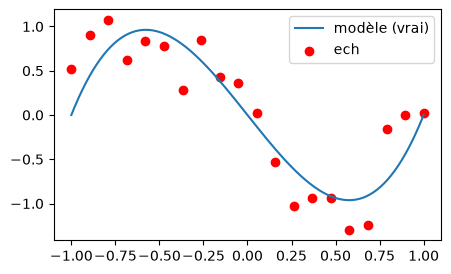

In [46]:
n = 20
sigma = 0.3
x_train = np.linspace(-1, 1, n)
y_train = cubic_gt(x_train)
y_train += np.random.randn(n)*sigma 
 
plt.figure(figsize=(5, 3))
plt.plot(x_true, y_true, label='modèle (vrai)')
plt.scatter(x_train, y_train, c='r', label='ech')
plt.legend()
plt.show()

L'objectif va être de prédire $y$ grâce à partir des données observées $x$.

## Estimation des paramètres du modèle

On fait l'hypothèse que l'on sait que les données suivent un polynôme de Legendre (le vrai paramètre $\beta = [0, -1, 0, 1]$ est inconnu).
L'objectif va être de déterminer $\hat{\beta}$ tel que
$$ \hat{\beta} = \arg \min_{\beta} \| X\beta - y \|^2.$$

On détermine alors $\hat{\beta} = X^\dagger y$, où $X^\dagger$ est la pseudo inverse de $X$ (que l'on peut calculer avec `numpy` grâce à l'instruction `np.linalg.pinv`).

#### Cas 1 : on connait le degré du polynome (degré $d=3$ ici car $\beta$ est en dimension 4)

<>:8: SyntaxWarning: invalid escape sequence '\h'
<>:8: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_614312/3384991703.py:8: SyntaxWarning: invalid escape sequence '\h'
  plt.plot(x_true, yHat_train, label='$\hat{y}$')


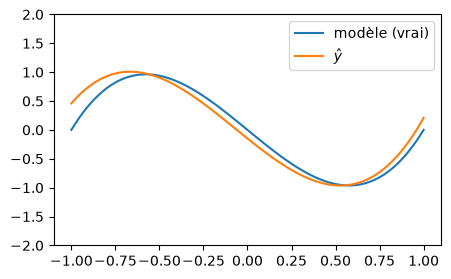

In [47]:
d = 3
betaHat = np.linalg.pinv(poly(x_train, d)).dot(y_train) #beta chapeau, estimé sur les données d'apprentissage
yHat_train = cubic_gt(x_true, betaHat) #y chapeau, sur toutes les données pour tracer la courbe

plt.figure(figsize=(5, 3))
plt.ylim(-2, 2)
plt.plot(x_true, y_true, label='modèle (vrai)')
plt.plot(x_true, yHat_train, label='$\hat{y}$')
plt.legend()
plt.show()

Et on calcule le RMSE (racine carrée de la moyenne des erreurs quadratiques) pour quantifier à quel point on se trompe sur l'échantillon :

In [48]:
yHatEch_train = cubic_gt(x_train, betaHat)
error_d_3 = np.sqrt(np.sum((y_train - yHatEch_train)**2))
print(f"RMSE : {error_d_3:.2f}")

RMSE : 1.23


#### Cas 2 : on ne connait pas le degré du polynôme

<div class="admonition note">
<p class="admonition-title"></p>
Tracer les estimations et calculer le RMSE pour `d = 1`, `d = 2`, `d = 3`, `d = 4`. Que constatez-vous ?

Faites la même chose (sur un graphique différent) pour `d = 10`, `d = 15`, `d = 20`. Que constatez-vous ?
</div>

d = 1, RMSE : 2.29
d = 2, RMSE : 2.18
d = 3, RMSE : 1.23
d = 4, RMSE : 1.17
d = 10, RMSE : 0.80
d = 15, RMSE : 0.39
d = 20, RMSE : 0.00


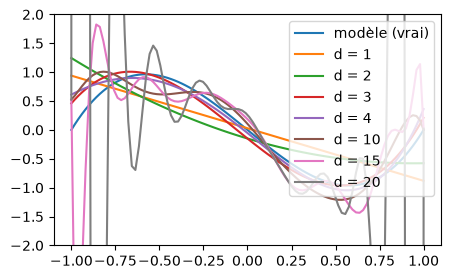

In [82]:
plt.figure(figsize=(5, 3))
plt.ylim(-2, 2)
plt.plot(x_true, y_true, label='modèle (vrai)')

for i in [1,2,3,4,10,15,20]:
    betaHat = np.linalg.pinv(poly(x_train, i)).dot(y_train) #beta chapeau, estimé sur les données d'apprentissage
    yHat_train = cubic_gt(x_true, betaHat) #y chapeau, sur toutes les données pour tracer la courbe
    yHatEch_train = cubic_gt(x_train, betaHat)
    error = np.sqrt(np.sum((y_train - yHatEch_train)**2))
    print(f"d = {i}, RMSE : {error:.2f}")

    plt.plot(x_true, yHat_train, label=f'd = {i}')

plt.legend()
plt.show()

## Evolution du RMSE en fonction de la complexité du modèle
### Sur l'échantillon d'apprentissage

Le degré du polynôme est une mesure de complexité du modèle : plus le degré est élevé, plus le modèle est complexe et est capable de capturer les "détails" et la complexité des données, mais aussi bien le "bruit" !
Le RMSE qu'on a calculé jusqu'à présent correspond à l'erreur en apprentissage (`training error`), c'est-à-dire que l'on évalue le modèle sur les données qui ont servi à l'ajuster.

<div class="admonition note">
<p class="admonition-title"></p>
Tracer l'évolution de l'erreur d'apprentissage pour différentes valeurs de $d$ comprises entre 0 et 20. On stockera les différentes valeurs de RMSE dans un array numpy nommé ``rmse_train``.
</div>

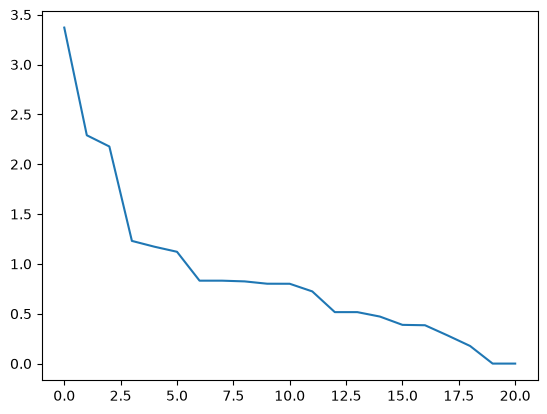

In [ ]:
rmse_train = []

for i in range(21):
    betaHat = np.linalg.pinv(poly(x_train, i)).dot(y_train) #beta chapeau, estimé sur les données d'apprentissage
    yHatEch_train = cubic_gt(x_train, betaHat)
    rmse_train.append(np.sqrt(np.sum((y_train - yHatEch_train)**2)))

plt.plot(range(21), rmse_train)
plt.show()

<div class="admonition note">
<p class="admonition-title"></p>
Commentez le résultat obtenu : est ce que cela vous parait cohérent ?
</div>

Cela parait cohérent car plus le degré est élévé, mieux le modèle peut s'adapter aux points (pas à la courbe), et donc plus l'erreur est faible

### Sur un échantillon de validation
On suppose maintenant que l'on a accès à 40 nouvelles données observées (bruitées encore une fois). On souhaite utiliser ces données pour **choisir** le meilleur modèle à conserver. 

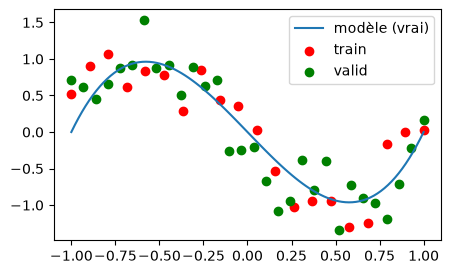

In [58]:
n = 30
sigma = 0.3

x_valid = np.linspace(-1, 1, n)
y_valid = cubic_gt(x_valid)
y_valid += np.random.randn(n)*sigma 
 
plt.figure(figsize=(5, 3))
plt.plot(x_true, y_true, label='modèle (vrai)')
plt.scatter(x_train, y_train, c='r', label='train')
plt.scatter(x_valid, y_valid, c='g', label="valid")
plt.legend()
plt.show()

On va évaluer les performances des modèles calculés **sur l'échantillon de train** sur les **données de validation**.
<div class="admonition note">
<p class="admonition-title"></p>
Tracer l'évolution de l'erreur sur l'échantillon de validation pour différentes valeurs de $d$ comprises entre 0 et 20. On stockera les différentes valeurs de RMSE dans un array numpy nommé ``rmse_valid``. On pourra également faire un zoom sur ce qui se passe pour $d$ compris entre 0 et 10.
</div>

1.644718410121035


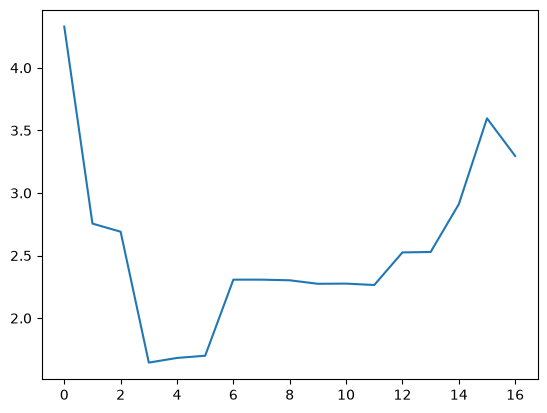

In [ ]:
rmse_valid = []

for i in range(21):
    betaHat = np.linalg.pinv(poly(x_train, i)).dot(y_train) #beta chapeau, estimé sur les données d'apprentissage
    yHatEch_valid = cubic_gt(x_valid, betaHat)
    rmse_valid.append(np.sqrt(np.sum((y_valid - yHatEch_valid)**2)))

plt.plot(range(21), rmse_valid)
print(min(rmse_valid))
plt.show()

<div class="admonition note">
<p class="admonition-title"></p>
Selon vous, quel est le meilleur degré ``d`` à choisir ? Quel est le RMSE associé sur l'échantillon de validation ?
</div>

on voit qu'au dela de d = 3, le RMSE réaugmente et particulièrement à partir de d = 17 : c'est du surapprentissage. Le meilleur d est donc 3

### Sur un échantillon de test
On a pour l'instant choisi le meilleur modèle en fonction de nos données d'apprentissage (qui ont servi à construire le modèle) et de nos données de validation (qui ont servi à choisir le meilleur modèle parmi un ensemble de modèles candidats). On souhaite maintenant être capable d'évaluer les performances du modèle en **généralisation**, c'est à dire de quantifier l'erreur à laquelle on peut s'attendre sur de nouvelles données (qui n'ont pas servi à construire le modèle, ni à le choisir).
On retire une nouvelle fois des données (25 données), que l'on nomme données de test (et stockées dans ``x_test`` et ``y_test``).


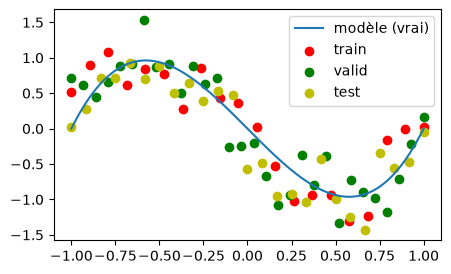

In [89]:
n = 25
sigma = 0.3

x_test = np.linspace(-1, 1, n)
y_test = cubic_gt(x_test)
y_test += np.random.randn(n)*sigma 
 
plt.figure(figsize=(5, 3))
plt.plot(x_true, y_true, label='modèle (vrai)')
plt.scatter(x_train, y_train, c='r', label='train')
plt.scatter(x_valid, y_valid, c='g', label="valid")
plt.scatter(x_test, y_test, c='y', label="test")
plt.legend()
plt.show()

<div class="admonition note">
<p class="admonition-title"></p>
En utilisant le modèle sélectionné sur l'échantillon de validation, quel est le RMSE obtenu sur l'échantillon de test ?
</div>

In [91]:
betaHat = np.linalg.pinv(poly(x_train, 3)).dot(y_train) #beta chapeau, estimé sur les données d'apprentissage
yHatEch_test = cubic_gt(x_test, betaHat)
print(f"RMSE : {np.sqrt(np.sum((y_test - yHatEch_test)**2))}")

RMSE : 1.513572700315706


<div class="admonition note">
<p class="admonition-title"></p>
Commentez sa valeur, notamment en le comparant au RMSE calculé sur l'échantillon de validation.
</div>

C'est un meilleur RMSE que la plus basse valeur de RMSE obtenue sur les données de validation

## Phénomène de la double descente

Pour des complexités trop faibles pour modéliser correctement les données, on dit que l'on fait du **sous-apprentissage** et lorsque les complexités sont trop impportantes et que l'on modélise le bruit, on dit que l'on fait du **sur-apprentissage**. Le problème se résume donc à trouver une complexité **optimale**. Cependant, les chercheurs se sont aperçus récemment que, après un **point d'interpolation**, on observait un phénomène de double descente : après être remontée (et donc être dans un régime de sur-apprentissage), l'erreur sur l'échantillon de validation finit par diminuer à nouveau.

On va étudier ce phénomène sur nos données.

<div class="admonition note">
<p class="admonition-title"></p>
Relancez les étapes de construction et de validation de modèles, mais cette fois ci en allant jusqu'à une complexité allant jusqu'à $d=40$. Que constatez-vous ? Quelle est la complexité correspondante au point d'interpolation ?
</div>

19


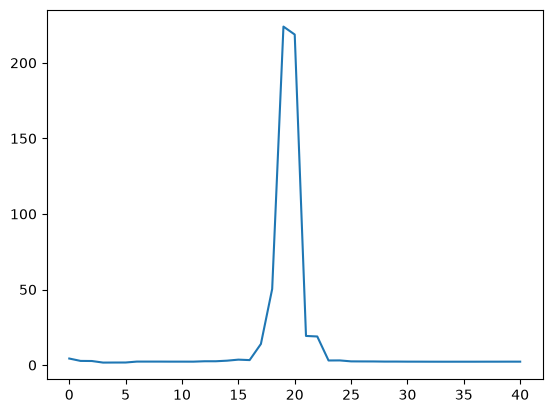

In [100]:
rmse_valid = []

for i in range(41):
    betaHat = np.linalg.pinv(poly(x_train, i)).dot(y_train) #beta chapeau, estimé sur les données d'apprentissage
    yHatEch_valid = cubic_gt(x_valid, betaHat)
    rmse_valid.append(np.sqrt(np.sum((y_valid - yHatEch_valid)**2)))

plt.plot(range(41), rmse_valid)
print(np.argmax(rmse_valid))
plt.show()

on constate que le sursaut de RMSE diminue aussi brutalement qu'il n'était arrivé. Il ne baisse pas jusqu'à un point aussi bas que pour d =3, mais reste comparable

<div class="admonition note">
<p class="admonition-title"></p>
Pour $d=40$, tracez le modèle correspondant et comparez-le à ce qu'on obtient pour $d = 20$. Faire la même chose pour $d = 1000$.
</div>

d = 20, RMSE : 108.21838271022442
d = 40, RMSE : 1.573842550552199
d = 1000, RMSE : 1.5549180609970699


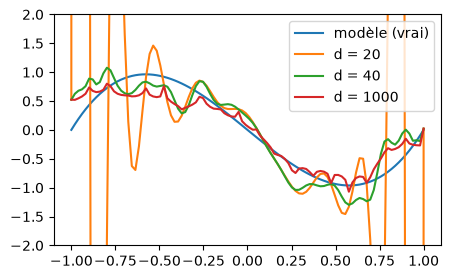

In [102]:
plt.figure(figsize=(5, 3))
plt.ylim(-2, 2)
plt.plot(x_true, y_true, label='modèle (vrai)')

for i in [20, 40, 1000]:
    betaHat = np.linalg.pinv(poly(x_train, i)).dot(y_train) #beta chapeau, estimé sur les données d'apprentissage
    yHat_train = cubic_gt(x_true, betaHat) #y chapeau, sur toutes les données pour tracer la courbe
    yHatEch_test = cubic_gt(x_test, betaHat)
    error = np.sqrt(np.sum((y_test - yHatEch_test)**2))
    print(f"d = {i}, RMSE : {error}")

    plt.plot(x_true, yHat_train, label=f'd = {i}')

plt.legend()
plt.show()

Ici, il est assez facile d'avoir une sur-paramétrisation des données car on a uniquement $n=20$ données dans notre échantillon d'apprentissage. Lorsque l'on a un volume considérable de données, il peut apparaitre, à première vue, difficile de sur-paramétriser. En pratique, avec l'amélioration des puissances de calcul et des techniques d'apprentissage (merci le deep learning !), on va pouvoir créer des modèles avec des **millions** ou des **milliards** (et plus encore) de paramètres qui vont nous permettre d'améliorer significativement les performances des algorithmes d'apprentissage sur des volumes impressionnants de données.

<div class="admonition attention">
Ce qu'on a vu dans cette partie : 

- les performances d'un modèle sont liées au volume des données disponibles, ainsi qu'à la complexité du modèle

- avec une complexité croissante, on a d'abord un régime de **sous-apprentissage**, puis un **régime optimal**, puis un régime de **sur-apprentissage**. Après un **point d'interpolation**, et pour un modèle **sur-paramétré**, les performances en généralisation s'améliorent ensuite jusqu'à éventuellement descendre en dessous des performances obtenues pour le régime optimal. C'est le phénomène de **double descente** qui a récemment été mis en évidence.

- l'échantillon d'apprentissage sert à **apprendre** (ou à estimer des paramètres) un modèle

- l'échantillon de validation sert à **comparer** des modèles entre eux afin de sélectionner le meilleur (i.e. celui avec les meilleurs performances sur de nouvelles données)

- l'échantillon de test sert à évaluer les performances **en généralisation** du modèle (i.e. sur des nouvelles données, qui n'ont pas servi à apprendre et à choisir le modèle).
</div>